# Why use Bayesian MCMC instead of Least Squares?

For the exposure–burial models considered here, parameter uncertainties are often large and asymmetric, and dependencies between parameters can be nonlinear. In such cases, the local linear approximation used to estimate the covariance matrix in least-squares fitting may not adequately describe the parameter uncertainties. Bayesian inference instead provides the full joint posterior distribution, allowing asymmetric uncertainties and nonlinear parameter dependencies to be captured and propagated to derived quantities such as event ages.

## Bayesian inference

When fitting a model to measured data $D$, we are interested in the probability distribution of the model parameters $\boldsymbol{\theta}$ given the observed data, $p(\boldsymbol{\theta}\mid D)$. However, the measurement model usually describes the reverse relationship, $p(D\mid\boldsymbol{\theta})$, i.e. how likely the observed data are for a given set of parameters. Bayes' theorem relates these two quantities:

$$
p(\boldsymbol{\theta}\mid D) =
\frac{p(D\mid\boldsymbol{\theta})\,p(\boldsymbol{\theta})}
{p(D)}.
$$

Here,

- $p(D\mid\boldsymbol{\theta})$ is the **likelihood**, describing how well a given set of parameters explains the observed data under the assumed measurement error model.
- $p(\boldsymbol{\theta})$ is the **prior**, describing our knowledge about the parameters before considering the data.
- $p(\boldsymbol{\theta}\mid D)$ is the **posterior**, describing our uncertainty about the parameters after taking the data into account.
- $p(D)$ is the **evidence**, which normalizes the posterior.

Since the observed data are fixed, the denominator is independent of the parameters and we can write

$$
p(\boldsymbol{\theta}\mid D)
\propto p(D\mid\boldsymbol{\theta})\,p(\boldsymbol{\theta}).
$$

For independent, normally distributed measurement errors, the likelihood is given by

$$
p(D\mid\boldsymbol{\theta}) =
\prod_{i=1}^{n}
\frac{1}{\sqrt{2\pi}\sigma_i}
\exp\left(
-\frac{(y_i-f(x_i;\boldsymbol{\theta}))^2}
{2\sigma_i^2}
\right).
$$

Unlike the covariance-based approach, this formulation does not require a local linear approximation of the model or assume that the resulting parameter distribution is Gaussian. The posterior follows directly from the assumed measurement error model, the observed data and the prior.

## Numerical evaluation of the posterior

In principle, the posterior can be calculated by evaluating the product of the likelihood and the prior on a sufficiently fine grid in parameter space and numerically normalizing the resulting distribution:

$$
p(\boldsymbol{\theta}\mid D) =
\frac{p(D\mid\boldsymbol{\theta})\,p(\boldsymbol{\theta})}
{\displaystyle\int
p(D\mid\boldsymbol{\theta}')\,p(\boldsymbol{\theta}')
\,\mathrm{d}\boldsymbol{\theta}'}.
$$

However, the number of grid points grows exponentially with the number of parameters. For $d$ parameters and $N$ grid points per parameter, a total of $N^d$ likelihood evaluations is required, making this approach impractical for higher-dimensional problems.

## Markov chain Monte Carlo (MCMC)

MCMC provides a more efficient way of approximating the posterior by generating samples rather than evaluating it on a regular grid. It constructs a Markov chain whose stationary distribution is the posterior, without requiring its normalization constant. The resulting samples can be used to estimate parameter distributions, dependencies and credible intervals, and to propagate uncertainties to derived quantities such as event ages.

The following code will show that there is a difference between the linearized least squares errors and the full Bayesian posterior.

Testing Least-Squares
Testing Bayesian MCMC

Fitting results:

Least-Squares Fit
t_exposure_1: 897.08, 68% confidence: 832.56 - 961.6, std: 64.52
Bayesian Fit
t_exposure_1: 901.71, 68% credible interval: 839.17 - 968.67, std: 64.67
Success: True
ESS: 554502.56


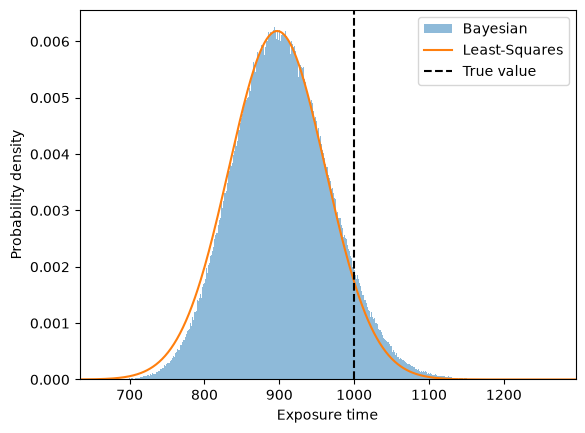

In [14]:
# run with PYTHONPATH=. python tests/test.py

from fitting_engine import FittingEngine
import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng()
engine = FittingEngine()

#########################
# True parameter values #
#########################

# true values used for generating the data
n_points = 30
true_y_err_std = 0.05

true_order = 0.0
true_sigma_phi = 5
true_mu = 5

# true values of the measured sample used for generating the data
true_t_exposure_1 = 1000

######################
# Generate test data #
######################

# generate measuremend sample data
x_data = np.linspace(0, 3, n_points)
y_data = engine.models.expo(x_data, true_order, true_sigma_phi, true_mu,
    true_t_exposure_1)
# add random perturbation
perturbation = np.random.normal(loc=0.0, scale=true_y_err_std,
    size=y_data.shape)
y_data += perturbation

#############################
# Different Fitting Methods #
#############################

# known parameters
known_params = {"order": true_order, "sigma_phi": true_sigma_phi,
    "mu": true_mu}
# known parameter distributions
known_params_distribution = {
    ("order",): (true_order, 0.0),
    ("sigma_phi",): (true_sigma_phi, 0.0),
    ("mu",): (true_mu, 0.0)}
# bounds for unknown parameters
free_params_bounds = {"t_exposure_1": (0, 100_000)}
initial_guess = {"t_exposure_1": true_t_exposure_1}
y_err_std = np.full(x_data.shape, true_y_err_std)

####################
# Least Sqaure Fit #
####################

print("Testing Least-Squares")
lstsq_fit_result = engine.easy_fit(x_data, y_data,
    engine.models.expo, known_params, initial_guess, y_err_std=y_err_std,
    only_positive=True)

lstsq_best_fit = lstsq_fit_result.best_fit["t_exposure_1"]
lstsq_std = lstsq_fit_result.std["t_exposure_1"]

#####################
# Bayesian MCMC Fit #
#####################

print("Testing Bayesian MCMC")
bayesian_fit_result = engine.bayesian_fit(100_000, 10_000,
    x_data, y_data, y_err_std, engine.models.expo, initial_guess,
    free_params_bounds, known_params_distribution, only_positive=True)

bayesian_samples = np.asarray(
    bayesian_fit_result.marginal_samples["t_exposure_1"])

################
# Plot results #
################

# get the full range of the posterior samples
lower, upper = bayesian_samples.min(), bayesian_samples.max()

# plot Bayesian posterior density
plt.hist(bayesian_samples, bins="fd", density=True, alpha=0.5,
    color="tab:blue", label="Bayesian")

# plot least squares Gaussian approximation
x = np.linspace(lower, upper, 500)
gauss = 1/(lstsq_std*np.sqrt(2*np.pi)) \
    * np.exp(-(x-lstsq_best_fit)**2/(2*lstsq_std**2))
plt.plot(x, gauss, color="tab:orange", label="Least-Squares")

plt.axvline(true_t_exposure_1, linestyle="--", color="black",
    label="True value")
plt.xlim(lower, upper)
plt.xlabel("Exposure time")
plt.ylabel("Probability density")
plt.legend()

#################
# Print results #
#################

print()
print("Fitting results:")
print()

print("Least-Squares Fit")
print(f"t_exposure_1: "
    f"{round(lstsq_fit_result.best_fit["t_exposure_1"], 2)}, 68% confidence: "
    f"{round(lstsq_best_fit - lstsq_std, 2)} - "
    f"{round(lstsq_best_fit + lstsq_std, 2)}, std: "
    f"{round(lstsq_fit_result.std["t_exposure_1"], 2)}")

print("Bayesian Fit")
print(f"t_exposure_1: "
    f"{round(bayesian_fit_result.best_fit["t_exposure_1"], 2)}, "
    f"68% credible interval: {round( \
    bayesian_fit_result.confidence_interval["t_exposure_1"][0], 2)} - "
    f"{round(\
    bayesian_fit_result.confidence_interval["t_exposure_1"][1], 2)}, std: "
    f"{round(bayesian_fit_result.std["t_exposure_1"], 2)}")
print(f"Success: {bayesian_fit_result.success}")
print(f"ESS: {round(bayesian_fit_result.ess["t_exposure_1"], 2)}")

plt.show()

One can see that the result of the Bayesian MCMC method is very similar to the distribution produced by the linearized model. The discrepancies become larger for larger values of `y_err_std` and fewer data points `n_points` because it weakens the linear assumption.